# 1. Tổng quan dữ liệu

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Tự tìm dataset từ thư mục notebook
current = Path.cwd().resolve()

DATA_PATH = None
SEARCH_ROOTS = [Path.cwd().resolve(), *Path.cwd().resolve().parents]

for folder in SEARCH_ROOTS:
    candidates = [
        folder / "data" / "raw" / "RT_IOT2022.csv",
        folder / "result" / "preprocessing" / "raw data" / "RT_IOT2022.csv",
        folder / "final_IoT" / "sample_project" / "result" / "preprocessing" / "raw data" / "RT_IOT2022.csv",
    ]
    for candidate in candidates:
        if candidate.is_file():
            DATA_PATH = candidate
            break
    if DATA_PATH is not None:
        break

if DATA_PATH is None:
    raise FileNotFoundError("Khong tim thay RT_IOT2022.csv trong cau truc project")

df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

display(df.head())

Kích thước dữ liệu: (123117, 85)
Số dòng: 123117
Số cột: 85


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


### Nhận xét: Tổng quan dữ liệu

- Bộ dữ liệu RT_IOT2022 gồm **123.117 bản ghi và 85 thuộc tính**.
- Các thuộc tính mô tả những đặc điểm liên quan đến lưu lượng mạng IoT.
- Dữ liệu bao gồm các thông tin về giao thức mạng, dịch vụ, thời gian và thống kê gói tin.

**Kết luận:** Bộ dữ liệu có quy mô tương đối lớn và nhiều thuộc tính, cần tiếp tục phân tích chất lượng dữ liệu, phân bố đặc trưng và phân bố nhãn trước khi xây dựng mô hình.

# 2. Kiểm tra cấu trúc dữ liệu

In [2]:
print("=== THÔNG TIN DATASET ===")
df.info()

print("\n=== THỐNG KÊ KIỂU DỮ LIỆU ===")
print(df.dtypes.value_counts())

print("\n=== DANH SÁCH TẤT CẢ THUỘC TÍNH ===")

columns_info = pd.DataFrame({
    "STT": range(1, len(df.columns) + 1),
    "Tên thuộc tính": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị khác nhau": df.nunique().values
})

display(columns_info)

=== THÔNG TIN DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 85 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  object 
 4   service                   123117 non-null  object 
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio     

,STT,Tên thuộc tính,Kiểu dữ liệu,Số giá trị khác nhau
0,1,Unnamed: 0,int64,94659
1,2,id.orig_p,int64,65478
2,3,id.resp_p,int64,1809
3,4,proto,object,3
4,5,service,object,10
...,...,...,...,...
80,81,idle.std,float64,1001
81,82,fwd_init_window_size,int64,20
82,83,bwd_init_window_size,int64,56
83,84,fwd_last_window_size,int64,109


### Nhận xét: Kiểu dữ liệu và thuộc tính

- Bộ dữ liệu có **82 thuộc tính dạng số** và **3 thuộc tính dạng object**.
- Các thuộc tính dạng object gồm `proto`, `service` và `Attack_type`.
- `Attack_type` là nhãn mục tiêu của bài toán phân loại.
- Phát hiện thuộc tính `bwd_URG_flag_count` chỉ chứa một giá trị duy nhất.
- Cột `Unnamed: 0` có khả năng là chỉ số được tạo khi xuất dữ liệu ra CSV.

**Kết luận:** Cần xem xét mã hóa các đặc trưng phân loại `proto` và `service`, đồng thời xem xét loại bỏ cột hằng và cột chỉ số trong giai đoạn tiền xử lý.

# 3. Kiểm tra chất lượng của dữ liệu

In [3]:
print("=== GIÁ TRỊ THIẾU ===")
print("Tổng giá trị thiếu:", df.isnull().sum().sum())

print("\n=== GIÁ TRỊ VÔ HẠN ===")

numeric_df = df.select_dtypes(include=np.number)

print("Tổng giá trị Inf:",
      np.isinf(numeric_df.to_numpy()).sum())

print("\n=== DỮ LIỆU TRÙNG LẶP ===")

# Kiểm tra toàn bộ các cột
print("Số dòng trùng toàn bộ:",
      df.duplicated().sum())

# Không sử dụng cột chỉ số trong phép so sánh
feature_cols = df.columns.drop("Unnamed: 0", errors="ignore")

print("Số dòng trùng khi bỏ Unnamed: 0:",
      df.duplicated(subset=feature_cols).sum())

print("\n=== CÁC CỘT CHỈ CÓ MỘT GIÁ TRỊ ===")

constant_cols = df.columns[df.nunique(dropna=False) == 1]

print(constant_cols.tolist())

=== GIÁ TRỊ THIẾU ===
Tổng giá trị thiếu: 0

=== GIÁ TRỊ VÔ HẠN ===
Tổng giá trị Inf: 0

=== DỮ LIỆU TRÙNG LẶP ===
Số dòng trùng toàn bộ: 0
Số dòng trùng khi bỏ Unnamed: 0: 5195

=== CÁC CỘT CHỈ CÓ MỘT GIÁ TRỊ ===
['bwd_URG_flag_count']


### Nhận xét: Chất lượng dữ liệu

- **Giá trị thiếu:** Không phát hiện giá trị thiếu.
- **Giá trị vô hạn:** Không phát hiện giá trị Inf.
- **Dữ liệu trùng lặp:** Khi xét toàn bộ 85 thuộc tính, không phát hiện dòng trùng hoàn toàn.
- Khi không xét cột `Unnamed: 0`, phát hiện **5.195 dòng trùng lặp**.
- **Thuộc tính hằng:** Phát hiện `bwd_URG_flag_count` chỉ có một giá trị duy nhất.

**Kết luận:**

- Bộ dữ liệu không cần xử lý giá trị thiếu hoặc vô hạn ở thời điểm khảo sát.
- Cần xem xét loại bỏ các bản ghi trùng lặp trong giai đoạn Data Cleaning.
- Cần xem xét loại bỏ các thuộc tính không mang thông tin phân biệt.
- Chưa thực hiện thay đổi dữ liệu trong giai đoạn EDA.

# 4. Thống kê mô tả các đặc trưng

In [4]:
# Không đưa cột chỉ số vào phân tích
numeric_df = df.select_dtypes(include=np.number).drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Tính thống kê mô tả
stats = numeric_df.describe().T

stats = stats.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std",
    "min": "Min",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Max"
})

# Bổ sung chỉ số để phát hiện vấn đề
stats["Skewness"] = numeric_df.skew()
stats["Zero_Percent"] = (
    numeric_df.eq(0).mean() * 100
)
stats["Unique_Values"] = numeric_df.nunique()

print("=== THỐNG KÊ MÔ TẢ ===")
display(stats.round(3))

# 1. Các thuộc tính có phân phối lệch mạnh
skewed = stats[
    stats["Skewness"].abs() > 3
].sort_values("Skewness", key=lambda x: x.abs(), ascending=False)

print("\n=== THUỘC TÍNH CÓ |SKEWNESS| > 3 ===")
print("Số lượng:", len(skewed))
display(
    skewed[
        ["Mean", "Median", "Std", "Skewness"]
    ].head(15).round(3)
)

# 2. Các thuộc tính chứa nhiều giá trị 0
zero_heavy = stats[
    stats["Zero_Percent"] >= 95
].sort_values("Zero_Percent", ascending=False)

print("\n=== THUỘC TÍNH CÓ >= 95% GIÁ TRỊ BẰNG 0 ===")
print("Số lượng:", len(zero_heavy))
display(
    zero_heavy[
        ["Min", "Median", "Max", "Zero_Percent"]
    ].round(3)
)

# 3. Các thuộc tính chỉ có một giá trị
constant = stats[
    stats["Unique_Values"] == 1
]

print("\n=== THUỘC TÍNH HẰNG ===")
display(constant[["Min", "Max", "Unique_Values"]])

=== THỐNG KÊ MÔ TẢ ===


,Count,Mean,Std,Min,Q1,Median,Q3,Max,Skewness,Zero_Percent,Unique_Values
id.orig_p,123117.0,34639.259,19070.620,0.0,17702.0,37221.0,50971.0,6.553500e+04,-0.234,0.002,65478
id.resp_p,123117.0,1014.305,5256.372,0.0,21.0,21.0,21.0,6.538900e+04,7.985,0.011,1809
flow_duration,123117.0,3.810,130.005,0.0,0.0,0.0,0.0,2.172834e+04,120.962,12.980,16383
fwd_pkts_tot,123117.0,2.269,22.337,0.0,1.0,1.0,1.0,4.345000e+03,121.437,0.036,163
bwd_pkts_tot,123117.0,1.910,33.018,0.0,1.0,1.0,1.0,1.011200e+04,249.909,12.369,172
...,...,...,...,...,...,...,...,...,...,...,...
idle.avg,123117.0,1664984.756,9007063.986,0.0,0.0,0.0,0.0,3.000000e+08,7.413,95.373,5670
idle.std,123117.0,45501.832,1091361.402,0.0,0.0,0.0,0.0,1.208029e+08,55.846,99.174,1001
fwd_init_window_size,123117.0,6118.905,18716.314,0.0,64.0,64.0,64.0,6.553500e+04,2.785,10.317,20
bwd_init_window_size,123117.0,2739.776,10018.849,0.0,0.0,0.0,0.0,6.553500e+04,4.271,91.586,56



=== THUỘC TÍNH CÓ |SKEWNESS| > 3 ===
Số lượng: 65


,Mean,Median,Std,Skewness
bwd_bulk_bytes,155.234,0.000,19592.952,340.498
bwd_bulk_packets,0.131,0.000,14.547,340.491
active.std,23535.992,0.000,1477934.783,287.993
bwd_pkts_payload.tot,512.998,0.000,42441.433,280.815
flow_pkts_payload.tot,734.517,120.000,42965.992,271.972
bwd_header_size_tot,46.627,20.000,1028.229,269.076
bwd_data_pkts_tot,0.820,0.000,32.294,264.031
bwd_pkts_tot,1.910,1.000,33.018,249.909
fwd_iat.min,8843.266,0.000,1226520.651,238.881
active.max,178589.771,4.053,3011783.924,234.462



=== THUỘC TÍNH CÓ >= 95% GIÁ TRỊ BẰNG 0 ===
Số lượng: 16


,Min,Median,Max,Zero_Percent
bwd_URG_flag_count,0.0,0.0,0.000000e+00,100.000
flow_CWR_flag_count,0.0,0.0,4.000000e+00,99.942
flow_ECE_flag_count,0.0,0.0,4.000000e+00,99.942
fwd_bulk_bytes,0.0,0.0,4.650950e+05,99.800
fwd_bulk_packets,0.0,0.0,3.430000e+02,99.800
fwd_bulk_rate,0.0,0.0,4.633628e+07,99.800
idle.std,0.0,0.0,1.208029e+08,99.174
bwd_bulk_bytes,0.0,0.0,6.805208e+06,99.101
bwd_bulk_rate,0.0,0.0,2.830087e+07,99.101
bwd_bulk_packets,0.0,0.0,5.052500e+03,99.101



=== THUỘC TÍNH HẰNG ===


,Min,Max,Unique_Values
bwd_URG_flag_count,0.0,0.0,1


### Nhận xét: Thống kê mô tả

**1. Phân phối dữ liệu**

- Phát hiện 65 thuộc tính số có độ lệch tuyệt đối
  (|Skewness|) lớn hơn 3.
- Một số thuộc tính như `bwd_bulk_bytes`,
  `bwd_bulk_packets`, `active.std` có độ lệch phải
  rất lớn.
- Điều này cho thấy nhiều đặc trưng không có
  phân phối đối xứng, phần lớn giá trị tập trung
  ở vùng thấp và có một số giá trị rất lớn.

**2. Đặc trưng chứa nhiều giá trị bằng 0**

- Phát hiện 16 thuộc tính có ít nhất 95%
  giá trị bằng 0.
- `flow_CWR_flag_count` có khoảng 99,94%
  giá trị bằng 0.
- `fwd_bulk_bytes` có khoảng 99,80%
  giá trị bằng 0.
- `bwd_URG_flag_count` có 100% giá trị bằng 0.

**3. Thang đo dữ liệu**

- Các đặc trưng có phạm vi giá trị khác nhau
  đáng kể.
- Ví dụ, `flow_duration` có giá trị lớn nhất
  khoảng 21.728, trong khi `flow_iat.tot`
  có giá trị lớn nhất trên 21 tỷ.
- Sự khác biệt thang đo có thể ảnh hưởng
  đến quá trình học của MLP.

**Kết luận:** Dataset có nhiều đặc trưng phân phối
lệch và thang đo không đồng nhất. Đây là những
vấn đề cần được phân tích sâu hơn trước khi
xây dựng pipeline tiền xử lý.

# 5. Phân tích phân bố nhãn

=== PHÂN BỐ NHÃN ===


,Số mẫu,Tỷ lệ (%)
Attack_type,,
DOS_SYN_Hping,94659,76.885
Thing_Speak,8108,6.586
ARP_poisioning,7750,6.295
MQTT_Publish,4146,3.368
NMAP_UDP_SCAN,2590,2.104
NMAP_XMAS_TREE_SCAN,2010,1.633
NMAP_OS_DETECTION,2000,1.624
NMAP_TCP_scan,1002,0.814
DDOS_Slowloris,534,0.434



Số lớp: 12
Lớp nhiều nhất: DOS_SYN_Hping
Lớp ít nhất: NMAP_FIN_SCAN
Tỷ lệ mất cân bằng: 3380.68:1


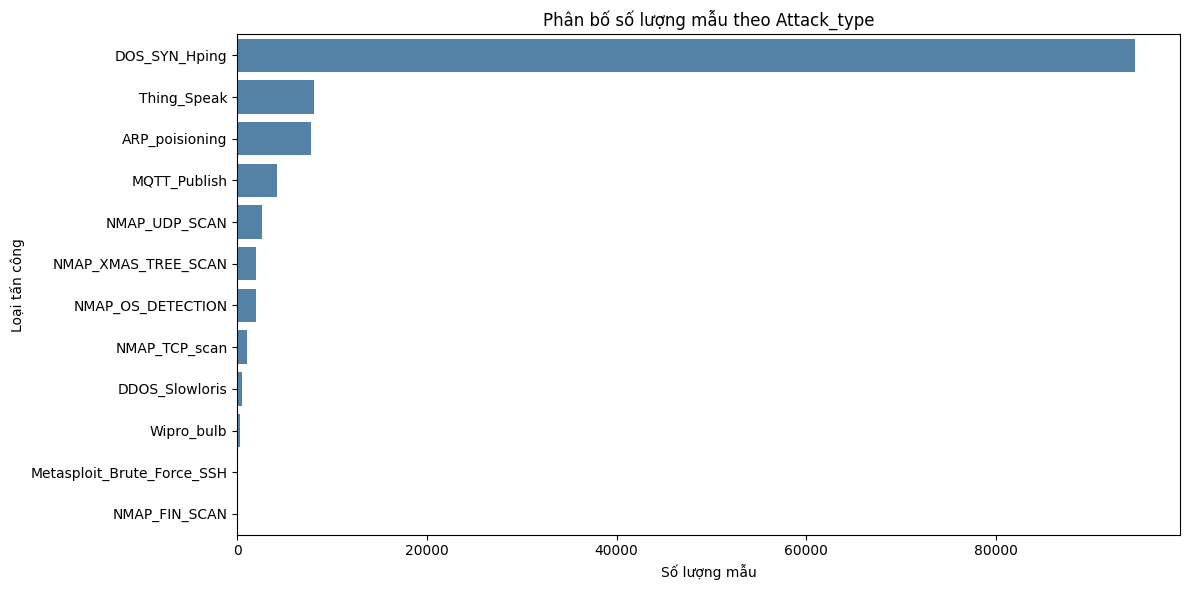

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

target = "Attack_type"

class_counts = df[target].value_counts()

class_distribution = pd.DataFrame({
    "Số mẫu": class_counts,
    "Tỷ lệ (%)": (
        class_counts / len(df) * 100
    ).round(3)
})

print("=== PHÂN BỐ NHÃN ===")
display(class_distribution)

print("\nSố lớp:", df[target].nunique())
print("Lớp nhiều nhất:", class_counts.idxmax())
print("Lớp ít nhất:", class_counts.idxmin())

imbalance_ratio = (
    class_counts.max() / class_counts.min()
)

print(f"Tỷ lệ mất cân bằng: {imbalance_ratio:.2f}:1")

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_counts.values,
    y=class_counts.index,
    color="steelblue"
)

plt.title("Phân bố số lượng mẫu theo Attack_type")
plt.xlabel("Số lượng mẫu")
plt.ylabel("Loại tấn công")

plt.tight_layout()
plt.show()

### Nhận xét: Phân bố nhãn mục tiêu

- Dataset gồm 12 lớp thuộc tính `Attack_type`.
- Phân bố số lượng mẫu giữa các lớp không đồng đều.
- Lớp `DOS_SYN_Hping` chiếm phần lớn dữ liệu,
  với 94.659 mẫu, tương đương khoảng 76,89%.
- Lớp `NMAP_FIN_SCAN` chỉ có 28 mẫu.
- Lớp `Metasploit_Brute_Force_SSH` chỉ có 37 mẫu.
- Tỷ lệ giữa lớp nhiều mẫu nhất và ít mẫu nhất
  khoảng 3.380,68:1.

**Kết luận:** Mất cân bằng lớp là một vấn đề
quan trọng cần xem xét trong quá trình xây dựng
và đánh giá mô hình MLP.

# 6. Các vấn đề được phát hiện từ dataset

In [6]:
import pandas as pd
import numpy as np

target = "Attack_type"

# Chỉ lấy đặc trưng số, không tính cột chỉ số
numeric_features = df.select_dtypes(
    include=np.number
).drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# 1. Chất lượng dữ liệu
missing_count = int(df.isna().sum().sum())

inf_count = int(
    np.isinf(numeric_features.to_numpy()).sum()
)

duplicate_count = int(
    df.duplicated(
        subset=df.columns.drop(
            "Unnamed: 0",
            errors="ignore"
        )
    ).sum()
)

# 2. Thuộc tính hằng
constant_cols = df.columns[
    df.nunique(dropna=False) == 1
].tolist()

# 3. Phân phối lệch
skewness = numeric_features.skew()

skewed_cols = skewness[
    skewness.abs() > 3
].index.tolist()

# 4. Nhiều giá trị bằng 0
zero_percentage = (
    numeric_features.eq(0).mean() * 100
)

high_zero_cols = zero_percentage[
    zero_percentage >= 95
].index.tolist()

# 5. Mất cân bằng nhãn
class_counts = df[target].value_counts()

imbalance_ratio = (
    class_counts.max() / class_counts.min()
)

# Tổng hợp vào bảng
issues = pd.DataFrame({
    "Vấn đề": [
        "Giá trị thiếu",
        "Giá trị vô hạn",
        "Dữ liệu trùng lặp",
        "Thuộc tính hằng",
        "Phân phối lệch mạnh |Skew| > 3",
        "Thuộc tính có >= 95% giá trị 0",
        "Mất cân bằng nhãn"
    ],
    "Kết quả": [
        missing_count,
        inf_count,
        duplicate_count,
        len(constant_cols),
        len(skewed_cols),
        len(high_zero_cols),
        round(imbalance_ratio, 2)
    ],
    "Hướng nghiên cứu": [
        "Xem xét xử lý nếu có",
        "Xem xét xử lý nếu có",
        "Kiểm tra trùng lặp trước khi chia dữ liệu",
        "Đánh giá loại bỏ đặc trưng hằng",
        "Phân tích Histogram, KDE, Boxplot",
        "Đánh giá độ hữu ích của đặc trưng",
        "Phân tích lớp hiếm và phương pháp cân bằng"
    ]
})

print("=== TỔNG HỢP VẤN ĐỀ DATASET ===")
display(issues)

print("\n=== DANH SÁCH CỘT HẰNG ===")
print(constant_cols)

print("\n=== CÁC THUỘC TÍNH LỆCH MẠNH NHẤT ===")
display(
    skewness.abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Absolute Skewness")
)

print("\n=== CÁC THUỘC TÍNH NHIỀU GIÁ TRỊ 0 NHẤT ===")
display(
    zero_percentage
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Zero (%)")
)

=== TỔNG HỢP VẤN ĐỀ DATASET ===


,Vấn đề,Kết quả,Hướng nghiên cứu
0,Giá trị thiếu,0.00,Xem xét xử lý nếu có
1,Giá trị vô hạn,0.00,Xem xét xử lý nếu có
2,Dữ liệu trùng lặp,5195.00,Kiểm tra trùng lặp trước khi chia dữ liệu
3,Thuộc tính hằng,1.00,Đánh giá loại bỏ đặc trưng hằng
4,Phân phối lệch mạnh |Skew| > 3,65.00,"Phân tích Histogram, KDE, Boxplot"
5,Thuộc tính có >= 95% giá trị 0,16.00,Đánh giá độ hữu ích của đặc trưng
6,Mất cân bằng nhãn,3380.68,Phân tích lớp hiếm và phương pháp cân bằng



=== DANH SÁCH CỘT HẰNG ===
['bwd_URG_flag_count']

=== CÁC THUỘC TÍNH LỆCH MẠNH NHẤT ===


,Absolute Skewness
bwd_bulk_bytes,340.497528
bwd_bulk_packets,340.490987
active.std,287.992755
bwd_pkts_payload.tot,280.814630
flow_pkts_payload.tot,271.972274
bwd_header_size_tot,269.075835
bwd_data_pkts_tot,264.030712
bwd_pkts_tot,249.909345
fwd_iat.min,238.881011
active.max,234.461542



=== CÁC THUỘC TÍNH NHIỀU GIÁ TRỊ 0 NHẤT ===


,Zero (%)
bwd_URG_flag_count,100.000000
flow_CWR_flag_count,99.942331
flow_ECE_flag_count,99.941519
fwd_bulk_bytes,99.800190
fwd_bulk_packets,99.800190
fwd_bulk_rate,99.800190
idle.std,99.173956
bwd_bulk_packets,99.100855
bwd_bulk_rate,99.100855
bwd_bulk_bytes,99.100855
